# Assignment 2: Introduction to Supervised Learning

In this assignment, I will load the California Housing dataset from scikit-learn, create visualizations to explore the data, and study the target variable, which is the median house value. Finally, I will split the dataset into training and testing sets so it is ready for a supervised learning model.

My steps:
- Load the dataset
- Create basic visualizations for exploratory data analysis (EDA)
- Understand the target variable and its distribution
- Split the dataset into training and testing sets
- Reflect on what I learned

## Step 1: Load the Dataset

In [1]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

In [2]:
# Load the California Housing dataset as a DataFrame
housing = fetch_california_housing(as_frame=True)
df = housing.frame

In [3]:
# Quick look at the data
print("Shape:", df.shape)
df.head()

Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


### Interpretation

I imported the libraries I need for this assignment: pandas for working with the data, matplotlib and seaborn for visualizations, and train_test_split from scikit-learn for splitting the data later.

I loaded the California Housing dataset as a DataFrame. It has 20,640 rows and 9 columns. Each row is one district in California. There are 8 features (MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude) and 1 target variable, MedHouseVal, which is the median house value in hundreds of thousands of dollars.

## Step 2: Basic Visualizations for Exploratory Data Analysis

### 2A: Distribution of Each Feature

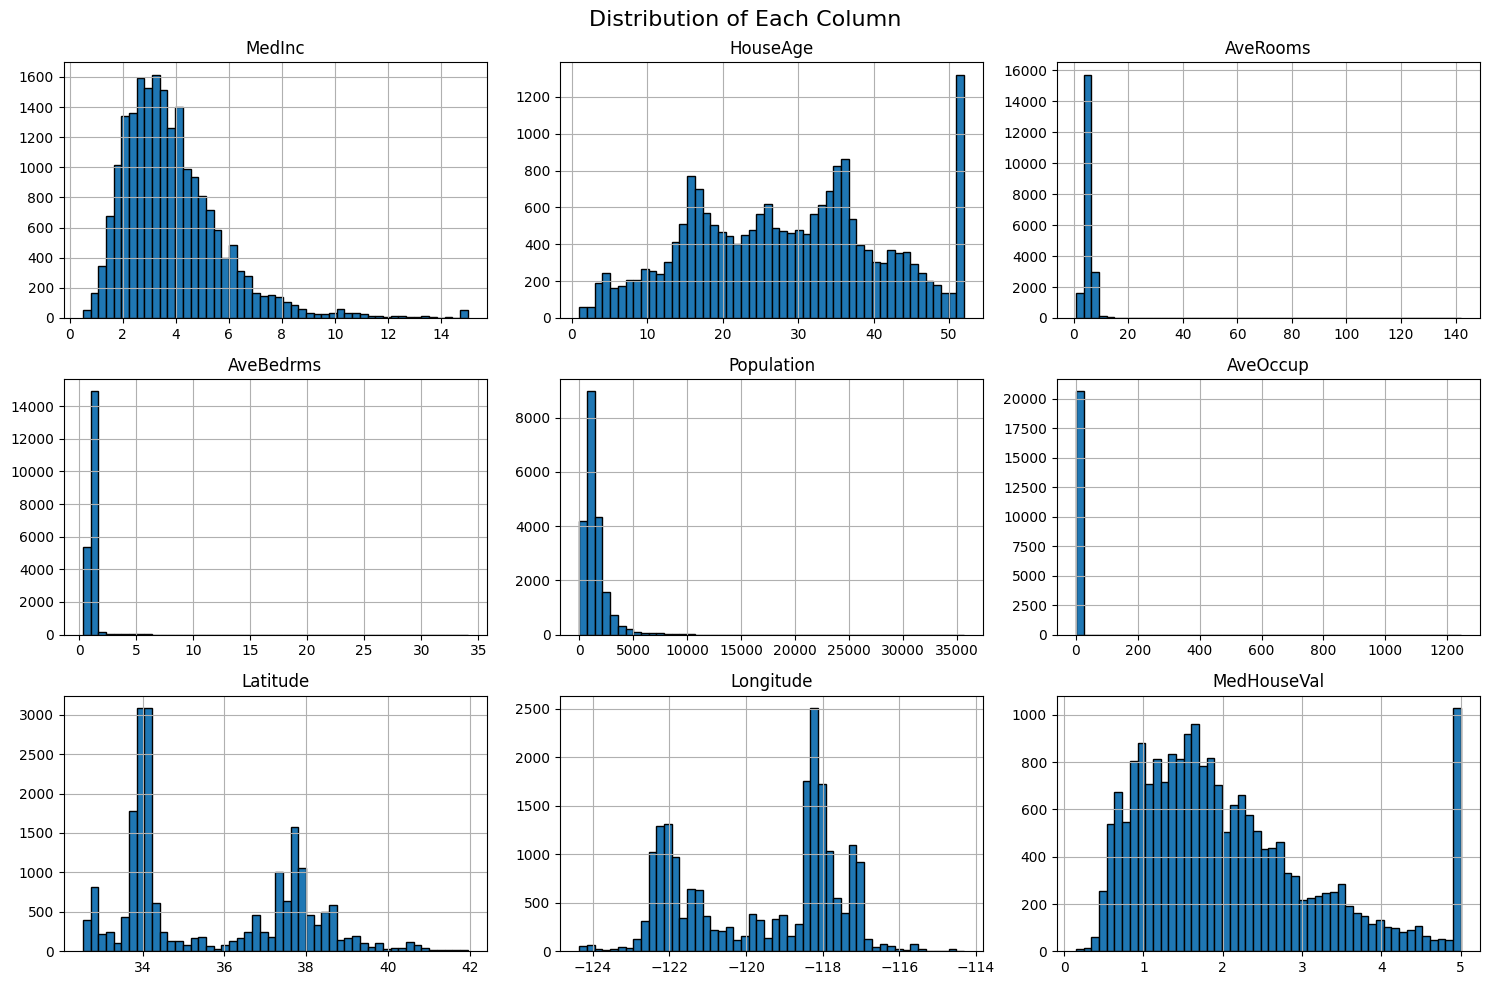

In [4]:
# Plot a histogram for every column
df.hist(bins=50, figsize=(15, 10), edgecolor="black")
plt.suptitle("Distribution of Each Column", fontsize=16)
plt.tight_layout()
plt.show()

### Interpretation

Each histogram shows how the values of one column are spread across the 20,640 districts. The x-axis shows the actual values of the column, and the y-axis shows how many districts fall into each range. I used bins=50, which splits each column's range into 50 equal-width bars. For example, MedInc goes from 0.5 to 15, so each bar covers about 0.29 (around $2,900).

What I noticed:
- MedInc is right-skewed. Most districts have a median income between 2 and 5 ($20,000 to $50,000), with a long tail to the right. There is a small spike at 15, which shows the values were capped.
- HouseAge is spread out fairly evenly, but there is a very tall spike at 52. This confirms that house ages above 52 were capped at 52.
- AveRooms, AveBedrms, Population, and AveOccup are all squeezed into one or two bars on the left side. This happens because a few extreme outliers stretch the x-axis very far (for example, AveOccup goes up to 1,243), so almost all normal values are pushed into the first bar.
- Latitude and Longitude each have two peaks. These match the two big population areas in California: the Los Angeles area (around latitude 34, longitude -118) and the San Francisco Bay Area (around latitude 37.5, longitude -122).
- MedHouseVal (the target) is right-skewed, with most districts between 1 and 2.5 ($100,000 to $250,000). There is a tall spike at 5.0, which confirms that house values above $500,000 were capped. About 1,000 districts sit at this cap.

### 2B: Relationship Between Median Income and House Value

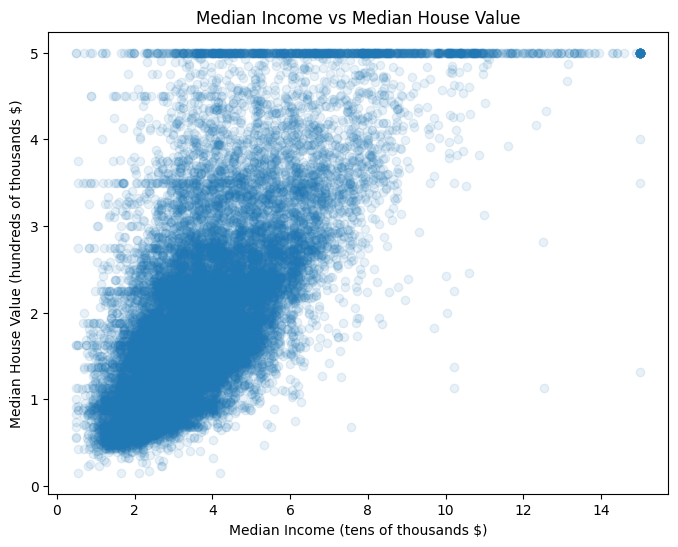

In [5]:
# Scatter plot of income vs house value
plt.figure(figsize=(8, 6))
plt.scatter(df["MedInc"], df["MedHouseVal"], alpha=0.1)
plt.xlabel("Median Income (tens of thousands $)")
plt.ylabel("Median House Value (hundreds of thousands $)")
plt.title("Median Income vs Median House Value")
plt.show()

### Interpretation

This scatter plot shows each district as one dot, with median income on the x-axis and median house value on the y-axis. I used alpha=0.1 to make the dots transparent, so darker areas show where many districts overlap.

What I noticed:
- There is a clear positive relationship. Districts with higher median income tend to have higher median house values. This makes sense because people with higher incomes can afford more expensive homes.
- The relationship is not perfect. The dots spread out more as income increases, which means income alone cannot fully predict house value. Other features like location probably matter too.
- There is a flat horizontal line of dots at 5.0. This is the cap on house values at $500,000. The real values of these districts could be much higher, which may make it harder for a model to predict expensive areas accurately.
- I can also see fainter horizontal lines at around 3.5, 4.5, and 2.75. These suggest some other values in the dataset were rounded or grouped.
- There is a dense group of dots at the top-right corner (income 15, value 5), where both income and house value are capped.
- Most districts are packed in the lower-left area, between income 2 to 5 and house value 0.5 to 2.5.

### 2C: Correlation Between All Columns

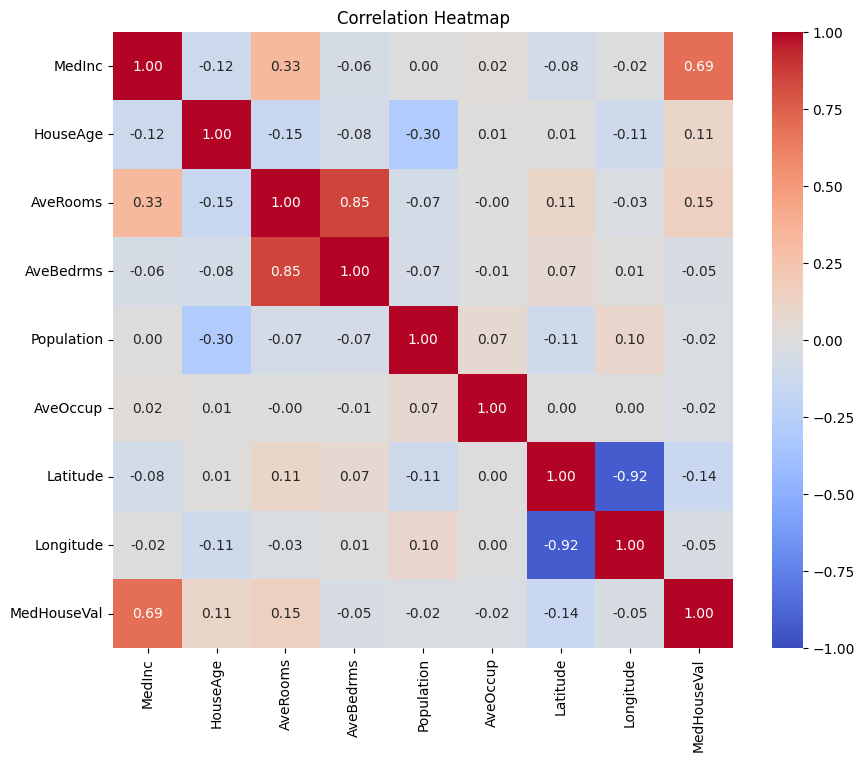

In [6]:
# Calculate correlation between all columns
corr = df.corr()

# Draw a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

### Interpretation

The heatmap shows the correlation between every pair of columns. Correlation goes from -1 to 1. Red means a positive relationship, blue means a negative relationship, and white means almost no straight-line relationship. The diagonal is always 1.00 because each column is perfectly related to itself.

What I noticed:
- MedInc has the strongest correlation with MedHouseVal (0.69). This confirms what I saw in the scatter plot: higher income districts tend to have higher house values. Median income is likely the most useful feature for predicting house value.
- All other features have weak correlations with MedHouseVal, between -0.14 and 0.15.
- AveRooms and AveBedrms are strongly correlated with each other (0.85). This makes sense because homes with more rooms usually have more bedrooms. Since they carry similar information, this is called multicollinearity, and it can affect some models like linear regression.
- Latitude and Longitude have a strong negative correlation (-0.92). This is not a real relationship between the two. It happens because California's shape runs diagonally, so as latitude increases (going north), longitude becomes more negative (going west).
- Latitude and Longitude have weak correlation with MedHouseVal, but this does not mean location is unimportant. Correlation only measures straight-line relationships. Location probably affects house value in a non-linear way, for example coastal areas being more expensive.

### 2D: House Value by Location

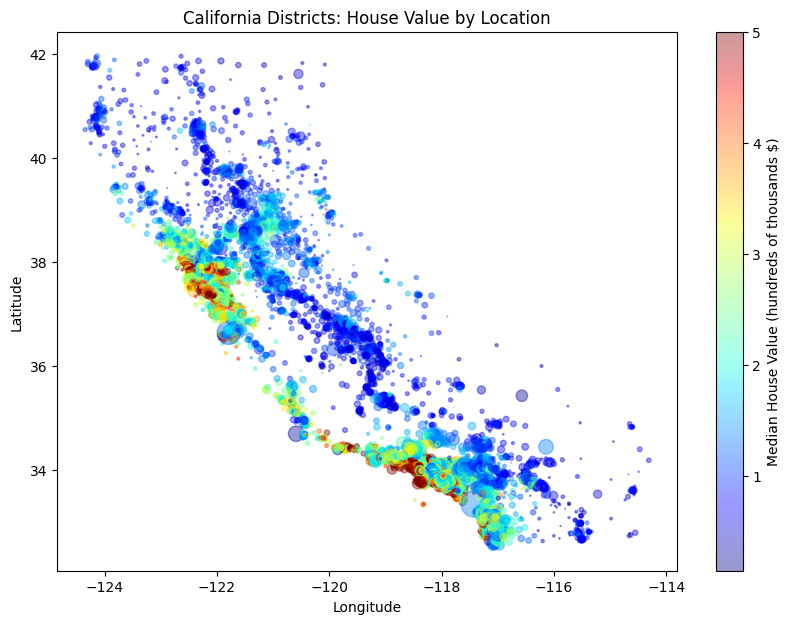

In [7]:
# Scatter plot of locations, coloured by house value
plt.figure(figsize=(10, 7))
plt.scatter(df["Longitude"], df["Latitude"],
            c=df["MedHouseVal"], cmap="jet",
            s=df["Population"] / 100, alpha=0.4)
plt.colorbar(label="Median House Value (hundreds of thousands $)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("California Districts: House Value by Location")
plt.show()

### Interpretation

In this chart, I plotted longitude on the x-axis and latitude on the y-axis, which draws the districts in the shape of California. Each dot is coloured by median house value (blue is cheaper, red is more expensive), and the dot size shows the population.

What I noticed:
- The most expensive districts (red and orange) are along the coast, especially around the San Francisco Bay Area (latitude about 37.5, longitude about -122) and the Los Angeles and San Diego areas (latitude about 34, longitude about -118).
- Inland districts, such as the Central Valley and northern California, are mostly blue, meaning lower house values.
- The larger dots, which represent higher population, are also mostly in the coastal city areas.
- This shows that location has a strong effect on house value, even though the correlation heatmap showed weak correlations for Latitude and Longitude. This is because the effect of location is not a straight line. Being close to the coast matters more than simply being further north or west. A model that can capture non-linear patterns, like a decision tree, may use location better than linear regression.

## Step 3: Understand the Target Variable (MedHouseVal)

In [8]:
# Summary statistics for the target
print(df["MedHouseVal"].describe().round(2))

count    20640.00
mean         2.07
std          1.15
min          0.15
25%          1.20
50%          1.80
75%          2.65
max          5.00
Name: MedHouseVal, dtype: float64


In [9]:
# How many districts are at the $500,000 cap?
capped = (df["MedHouseVal"] >= 5.0).sum()
print("\nDistricts at the cap (5.0):", capped)
print("Percentage at the cap:", round(capped / len(df) * 100, 2), "%")


Districts at the cap (5.0): 992
Percentage at the cap: 4.81 %


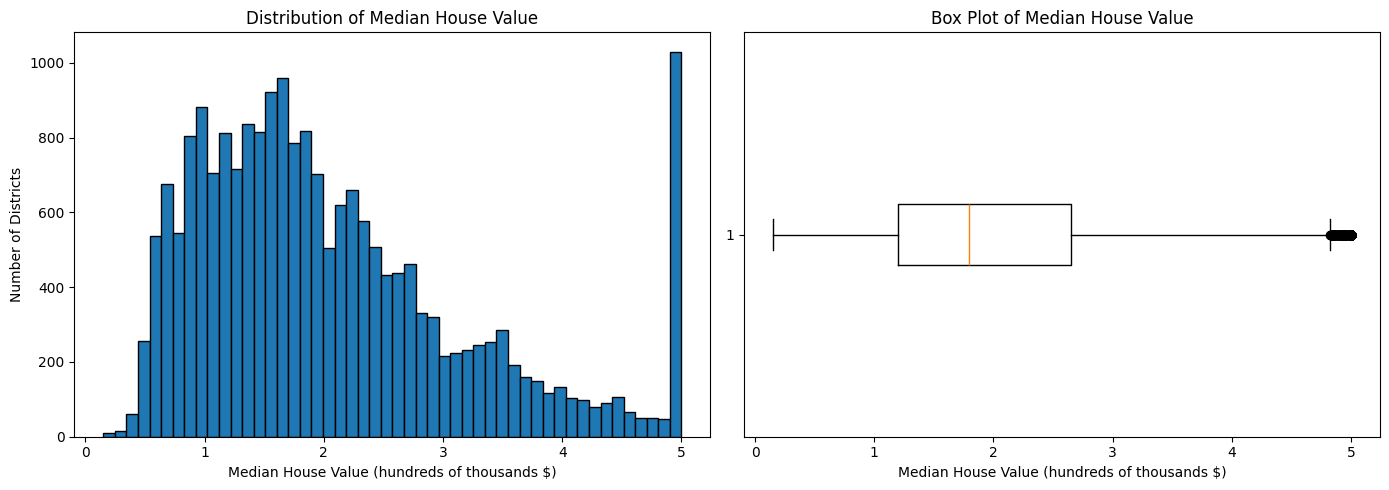

In [10]:
# Histogram and box plot side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df["MedHouseVal"], bins=50, edgecolor="black")
axes[0].set_title("Distribution of Median House Value")
axes[0].set_xlabel("Median House Value (hundreds of thousands $)")
axes[0].set_ylabel("Number of Districts")

axes[1].boxplot(df["MedHouseVal"], vert=False)
axes[1].set_title("Box Plot of Median House Value")
axes[1].set_xlabel("Median House Value (hundreds of thousands $)")

plt.tight_layout()
plt.show()


### Interpretation

The target variable is MedHouseVal, the median house value of each district in hundreds of thousands of dollars. Since it is a continuous number, this is a regression problem.

From the summary statistics, house values range from 0.15 ($15,000) to 5.00 ($500,000), with a median of 1.80 ($180,000) and a mean of 2.07 ($207,000). The mean is higher than the median, which means the distribution is right-skewed.

I found that 992 districts (about 4.81% of the dataset) have a value of 5.0 or higher. This confirms that house values were capped at $500,000.

From the histogram:
- Most districts have house values between 0.5 and 2.5 ($50,000 to $250,000).
- The distribution has a long tail to the right, which shows it is right-skewed.
- There is a very tall bar at 5.0, which is the capped values. This bar is much taller than the bars around it, which is not natural.

From the box plot:
- The box shows the middle 50% of districts, from about 1.2 to 2.65 ($120,000 to $265,000).
- The orange line inside the box is the median, at about 1.8.
- The whisker on the right ends at about 4.8. Values above this are shown as outliers, and they form a thick black group near 5.0 because so many districts are capped there.

The cap is a problem for modelling, because the model will never see house values above $500,000. It may predict expensive districts too low. One option would be to remove the capped rows before training, but for this assignment I will keep them.

## Step 4: Split the Dataset into Training and Testing Sets

In [11]:
# Separate features (X) and target (y)
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Check the sizes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# Compare the target in both sets
print("\nMean house value - train:", round(y_train.mean(), 3))
print("Mean house value - test:", round(y_test.mean(), 3))

X_train shape: (16512, 8)
X_test shape: (4128, 8)
y_train shape: (16512,)
y_test shape: (4128,)

Mean house value - train: 2.072
Mean house value - test: 2.055


### Interpretation

I separated the data into features (X) and the target (y). X contains the 8 feature columns, and y contains only MedHouseVal, the value I want to predict.

I then used train_test_split to split the data into 80% training and 20% testing. I set random_state=42 so the split is the same every time I run the notebook.

Results:
- X_train has 16,512 rows and 8 columns, and X_test has 4,128 rows and 8 columns.
- y_train has 16,512 values, and y_test has 4,128 values. The shape shows only one number because y is a single column, so it has only one dimension.
- 16,512 + 4,128 = 20,640, which matches the total number of rows, so no data was lost.
- The mean house value is 2.072 in the training set and 2.055 in the testing set. These are very close, which means the random split gave both sets a similar range of house values. This is important because the test set should represent the same kind of data the model learns from.

The training set will be used to teach the model, and the testing set will be kept separate to check how well the model performs on data it has never seen.

## Step 5: Reflection

### What are the key takeaways from the exploratory data analysis?
- The dataset has 20,640 districts, 8 numeric features, and no missing values, so it is clean and easy to work with.
- The target, MedHouseVal, is right-skewed and capped at $500,000. About 4.81% of districts are at this cap.
- MedInc, HouseAge, and MedHouseVal all have capped values, which shows up as tall spikes at the end of their histograms.
- The features are on very different scales, so feature scaling may be needed for some models.

### Based on the visualizations, what can I say about the relationships between features?
- AveRooms and AveBedrms are strongly related (0.85), which makes sense because homes with more rooms usually have more bedrooms. They carry similar information.
- Latitude and Longitude have a strong negative correlation (-0.92), but this is because of California's diagonal shape, not a real relationship.
- Most other features have weak relationships with each other.

### Do I observe any outliers?
Yes:
- AveOccup has extreme outliers, with one district showing about 1,243 people per household, while most districts have around 3.
- AveRooms (up to 141) and AveBedrms (up to 34) also have extreme values. These outliers squeezed most of the histogram data into one or two bars.
- Population goes up to 35,682, while most districts are under 2,000.
- In the box plot of MedHouseVal, the values near 5.0 appear as outliers because of the $500,000 cap.